# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
import hashlib
from sklearn.model_selection import train_test_split

# 1. Asignación del ID del estudiante
ID_ESTUDIANTE = 4
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

# 2. Selección de la muestra individual (35.000 registros)
muestra, _ = train_test_split(data, train_size=35000,
                              random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

# 3. Partición de datos:
#    - Train: 70% (24.500)
#    - Valid: 15% (5.250)
#    - Test:  15% (5.250)
train, temporal = train_test_split(muestra, test_size=0.30,
                                   random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                                random_state=semilla, stratify=temporal['is_late'])

# 4. Definición de columnas de características.
#    Solo las 28 variables disponibles al cierre de la compra (sección 2).
#    No se usan todas las columnas de `muestra`: incluirían dias_entrega y las
#    fechas reales de entrega, que contienen la respuesta (fuga de datos).
columnas = columnas_numericas + columnas_categoricas

# 5. Creación de conjuntos de entrenamiento, validación y prueba
X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']
X_test, y_test = test[columnas], test['is_late']

# 6. Generación de huella y verificación de tamaños
huella_muestra = hashlib.sha256('|'.join(muestra['order_id'].astype(str)).encode()).hexdigest()[:12]

print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 04 | Semilla: 1004
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: db4dadcc4303


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

# 1. Identificación automática de tipos de variables
columnas_numericas = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
columnas_categoricas = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# 2. Objeto de preprocesamiento
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                                StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                  OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

# 3. Ajustar el preprocesador únicamente con los datos de entrenamiento
preprocesamiento.fit(X_train)

# 4. Modelo de referencia (DummyClassifier)
referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

# 5. Métricas de desempeño del modelo de referencia
print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


/tmp/ipykernel_279/1765033636.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# TODO 1. Entrene el modelo y genere predicciones.
# Elección de ponderación: 'balanced' es recomendable cuando la variable objetivo está desbalanceada (ej. pocos retrasos)
peso_clases = 'balanced'  # Opción: None o 'balanced'

# Creación del Pipeline completo (preprocesamiento + regresión logística)
modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=peso_clases, max_iter=1000, random_state=semilla)
)

# Entrenamiento del pipeline en el conjunto de entrenamiento
modelo.fit(X_train, y_train)

# Generación de predicciones en el conjunto de validación
pred = modelo.predict(X_valid)

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

Accuracy: 0.6621
Precision: 0.1221
Recall: 0.6433
F1: 0.2052
Roc_auc: 0.7162
Ap: 0.1509


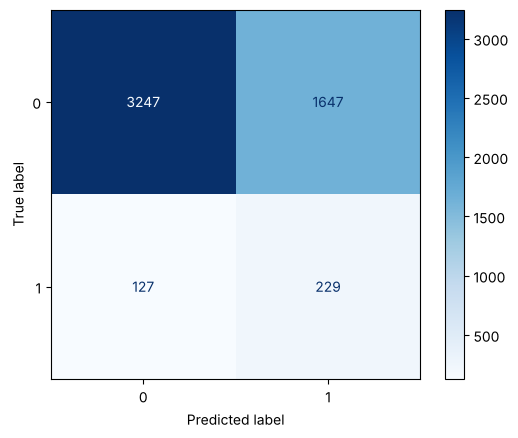

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

# TODO 2. Calcule las métricas y muestre la matriz de confusión.

# 1. Obtener probabilidades de la clase positiva (is_late = 1)
proba = modelo.predict_proba(X_valid)[:, 1]

# 2. Calcular diccionario de métricas
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}

# Impresión de métricas formateadas
for metrica, valor in medidas.items():
    print(f'{metrica.capitalize()}: {valor:.4f}')

# 3. Mostrar la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_valid, pred, cmap='Blues')

### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [11]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
resumen_segmentos = (
    analisis.groupby(['mes_compra', 'customer_state'])
    .agg(
        cantidad_pedidos=('error', 'count'),
        tasa_error=('error', 'mean')
    )
    .reset_index()
)

# Convertir la tasa a porcentaje (0-100%) para facilitar la interpretación
resumen_segmentos['porcentaje_error'] = resumen_segmentos['tasa_error'] * 100

# Ordenar por mayor tasa de error para identificar los segmentos más críticos
resumen_segmentos = resumen_segmentos.sort_values(by='porcentaje_error', ascending=False)

# Mostrar el resultado
display(resumen_segmentos)

,mes_compra,customer_state,cantidad_pedidos,tasa_error,porcentaje_error
217,10,PB,1,1.0,100.0
212,10,MA,2,1.0,100.0
227,10,TO,1,1.0,100.0
225,10,SE,1,1.0,100.0
221,10,RN,1,1.0,100.0
...,...,...,...,...,...
198,9,PR,10,0.0,0.0
61,3,RN,1,0.0,0.0
205,10,AC,1,0.0,0.0
261,12,PB,3,0.0,0.0


In [12]:
# Complemento de la Actividad 3: los segmentos con 1 a 3 pedidos dominan el ranking.
# Se repite el análisis exigiendo un tamaño mínimo para que la tasa sea interpretable.
MIN_PEDIDOS = 30
print('Segmentos mes x estado con al menos', MIN_PEDIDOS, 'pedidos:')
display(resumen_segmentos[resumen_segmentos['cantidad_pedidos'] >= MIN_PEDIDOS].head(8).round(2))

por_estado = (analisis.groupby('customer_state')
              .agg(cantidad_pedidos=('error', 'count'), porcentaje_error=('error', 'mean'),
                   tasa_tardia_real=('is_late', 'mean'))
              .assign(porcentaje_error=lambda d: 100 * d['porcentaje_error'],
                      tasa_tardia_real=lambda d: 100 * d['tasa_tardia_real']))
print('Estados con al menos 100 pedidos (mayor error):')
display(por_estado[por_estado['cantidad_pedidos'] >= 100].sort_values('porcentaje_error', ascending=False).head(6).round(2))

por_mes = (analisis.groupby('mes_compra')
           .agg(cantidad_pedidos=('error', 'count'), porcentaje_error=('error', 'mean'),
                tasa_tardia_real=('is_late', 'mean'))
           .assign(porcentaje_error=lambda d: 100 * d['porcentaje_error'],
                   tasa_tardia_real=lambda d: 100 * d['tasa_tardia_real']))
print('Meses (mayor error):')
display(por_mes.sort_values('porcentaje_error', ascending=False).head(5).round(2))

Segmentos mes x estado con al menos 30 pedidos:


,mes_compra,customer_state,cantidad_pedidos,tasa_error,porcentaje_error
176,8,RJ,53,0.79,79.25
199,9,RJ,36,0.78,77.78
220,10,RJ,38,0.71,71.05
242,11,RJ,70,0.70,70.00
151,7,RJ,62,0.68,67.74
102,5,RJ,71,0.68,67.61
37,2,RJ,66,0.64,63.64
265,12,RJ,37,0.62,62.16


Estados con al menos 100 pedidos (mayor error):


,cantidad_pedidos,porcentaje_error,tasa_tardia_real
customer_state,,,
ES,116,69.83,9.48
BA,189,64.55,14.29
RJ,658,64.44,13.07
SC,189,49.21,8.47
GO,113,39.82,4.42
RS,280,38.57,7.14


Meses (mayor error):


,cantidad_pedidos,porcentaje_error,tasa_tardia_real
mes_compra,,,
8,569,51.67,4.92
7,526,41.63,3.61
9,255,40.00,4.31
10,266,39.85,3.76
11,412,34.71,15.05


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [13]:
from sklearn.metrics import confusion_matrix

# TODO 4. Calcule el costo total con la matriz de confusión.
# Extraer los elementos de la matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

costo_fp = 8   # Costo por falso positivo (R$ 8)
costo_fn = 35  # Costo por falso negativo (R$ 35)

# Cálculo del costo total
costo_fp_fn = (fp * costo_fp) + (fn * costo_fn)

print(f'Falsos Positivos (FP): {fp}')
print(f'Falsos Negativos (FN): {fn}')
print(f'Costo total de errores: R$ {costo_fp_fn:,.2f}')

Falsos Positivos (FP): 1647
Falsos Negativos (FN): 127
Costo total de errores: R$ 17,621.00


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [14]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


In [15]:
from sklearn.base import clone
# Comparación de ponderación de clases (Actividad 1): mismo pipeline, solo cambia class_weight.
filas_cw = []
for opcion in [None, 'balanced']:
    m_cw = make_pipeline(clone(preprocesamiento),
                         LogisticRegression(class_weight=opcion, max_iter=1000, random_state=semilla))
    m_cw.fit(X_train, y_train)
    p_cw = m_cw.predict(X_valid)
    tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_valid, p_cw).ravel()
    filas_cw.append({'class_weight': str(opcion),
                     'accuracy': accuracy_score(y_valid, p_cw),
                     'precision': precision_score(y_valid, p_cw, zero_division=0),
                     'recall': recall_score(y_valid, p_cw, zero_division=0),
                     'f1': f1_score(y_valid, p_cw, zero_division=0),
                     'roc_auc': roc_auc_score(y_valid, m_cw.predict_proba(X_valid)[:, 1]),
                     'FP': fp_c, 'FN': fn_c, 'costo_brl': 8 * fp_c + 35 * fn_c})
display(pd.DataFrame(filas_cw).set_index('class_weight').round(4))

,accuracy,precision,recall,f1,roc_auc,FP,FN,costo_brl
class_weight,,,,,,,,
None,0.9322,0.0000,0.0000,0.0000,0.7150,0,356,12460
balanced,0.6621,0.1221,0.6433,0.2052,0.7162,1647,127,17621


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [16]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

# Cada modelo recibe una copia independiente del preprocesamiento.
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr', random_state=semilla))

# Entrenamiento con la variable objetivo continua 'dias_entrega'
modelo_reg.fit(X_train, train['dias_entrega'])

# Generación de predicciones de días en validación
pred_dias = modelo_reg.predict(X_valid)

# Cálculo y visualización del MAE (Error Absoluto Medio)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)
print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.19 días


## Actividades de la semana 12 (PCA, costos y KS)

Se agregan cinco actividades sobre el mismo `preprocesamiento`, la misma muestra y las mismas particiones. Todo se ajusta solo con `train` y se evalúa en `valid`. Los datos de `test` no se usan para elegir modelos.

### Actividad 5. Varianza explicada acumulada (PCA)

Se aplica PCA sobre la matriz ya preprocesada (numéricas imputadas y escaladas + categóricas con One-Hot), ajustada solo con `train`. Se registra el número de componentes necesario para retener 90 %, 95 % y 99 % de la varianza.

Matriz preprocesada (train): (24500, 145)
90% de varianza -> 18 componentes de 145 (12.4% de las variables preprocesadas)
95% de varianza -> 29 componentes de 145 (20.0% de las variables preprocesadas)
99% de varianza -> 58 componentes de 145 (40.0% de las variables preprocesadas)
Primer componente: 20.38% de la varianza


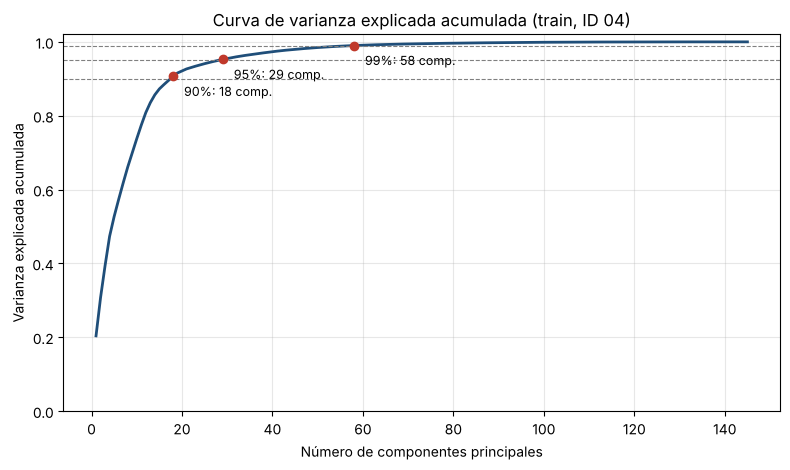

Figura guardada en reports/figuras/S12_curva_varianza_ID_04.png


In [17]:
from sklearn.base import clone
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

FIG_DIR = Path('reports/figuras')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# PCA no admite matrices dispersas: se fuerza salida densa en el preprocesamiento.
prep_denso = clone(preprocesamiento).set_params(sparse_threshold=0)
Z_train = prep_denso.fit_transform(X_train)
print('Matriz preprocesada (train):', Z_train.shape)

pca_completo = PCA(random_state=semilla).fit(Z_train)
var_acum = np.cumsum(pca_completo.explained_variance_ratio_)

# Mismo criterio de sklearn: primer k con varianza acumulada > umbral
umbrales = [0.90, 0.95, 0.99]
n_comp = {u: int(np.searchsorted(var_acum, u, side='right') + 1) for u in umbrales}
n_total = Z_train.shape[1]
for u, k in n_comp.items():
    print(f'{int(u*100)}% de varianza -> {k} componentes de {n_total} '
          f'({100*k/n_total:.1f}% de las variables preprocesadas)')
print(f'Primer componente: {100*pca_completo.explained_variance_ratio_[0]:.2f}% de la varianza')

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(np.arange(1, n_total + 1), var_acum, color='#1f4e79', lw=2)
for u, k in n_comp.items():
    ax.axhline(u, color='gray', ls='--', lw=0.8)
    ax.plot(k, var_acum[k-1], 'o', color='#c0392b')
    ax.annotate(f'{int(u*100)}%: {k} comp.', (k, var_acum[k-1]),
                textcoords='offset points', xytext=(8, -14), fontsize=9)
ax.set_xlabel('Número de componentes principales')
ax.set_ylabel('Varianza explicada acumulada')
ax.set_title(f'Curva de varianza explicada acumulada (train, ID {identificador})')
ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
fig.tight_layout()
ruta_curva = FIG_DIR / f'S12_curva_varianza_ID_{identificador}.png'
fig.savefig(ruta_curva, dpi=150)
plt.show()
print('Figura guardada en', ruta_curva)

**Resultado e interpretación (Actividad 5).** Después del preprocesamiento hay 145 variables (24 numéricas y 121 columnas One-Hot). El primer componente explica solo 20.38 % de la varianza, y la curva sube de forma gradual:

| Varianza acumulada | Componentes | % de las 145 variables |
|---|---|---|
| 90 % | **18** | 12.4 % |
| 95 % | **29** | 20.0 % |
| 99 % | **58** | 40.0 % |

*Utilidad para el problema:* PCA permite resumir el pedido en pocas direcciones no correlacionadas. Esto sirve porque varias variables están relacionadas entre sí (por ejemplo `valor_pagado` incluye `valor_productos` y `valor_flete`, y el peso y el volumen suelen crecer juntos), y porque las 121 columnas One-Hot de estado y categoría hacen la matriz ancha y poco densa. Con 18 componentes se conserva el 90 % de la varianza con 12 % de las variables, lo que reduce el costo de cómputo y la multicolinealidad. Como PCA no usa `is_late`, retener varianza no garantiza retener la señal que predice el retraso; eso se comprueba en la Actividad 6. Además, los componentes mezclan todas las variables y se pierde la interpretación directa de los coeficientes.

### Actividad 6. Comparación de cuatro configuraciones

Se entrena la misma regresión logística (`class_weight='balanced'`, `max_iter=1000`) con cuatro representaciones de las variables: sin PCA y con PCA reteniendo 90 %, 95 % y 99 % de la varianza. Las métricas se calculan en validación con las mismas funciones de la Actividad 2.

In [18]:
import time, warnings
from sklearn.exceptions import ConvergenceWarning

def construir(n_componentes=None):
    pasos = [clone(preprocesamiento).set_params(sparse_threshold=0)]
    if n_componentes is not None:
        pasos.append(PCA(n_components=n_componentes, random_state=semilla))
    pasos.append(LogisticRegression(class_weight=peso_clases, max_iter=1000,
                                    random_state=semilla))
    return make_pipeline(*pasos)

configuraciones = {
    'Sin PCA': None,
    'PCA 90%': n_comp[0.90],
    'PCA 95%': n_comp[0.95],
    'PCA 99%': n_comp[0.99],
}

modelos_cfg, filas, predicciones = {}, [], {}
for nombre, k in configuraciones.items():
    m = construir(k)
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        m.fit(X_train, y_train)
    segundos = time.perf_counter() - t0
    convergio = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)

    p_cfg = m.predict(X_valid)
    pr_cfg = m.predict_proba(X_valid)[:, 1]
    modelos_cfg[nombre] = m
    predicciones[nombre] = p_cfg
    filas.append({
        'configuracion': nombre,
        'n_variables_modelo': n_total if k is None else k,
        'accuracy': accuracy_score(y_valid, p_cfg),
        'precision': precision_score(y_valid, p_cfg, zero_division=0),
        'recall': recall_score(y_valid, p_cfg, zero_division=0),
        'f1': f1_score(y_valid, p_cfg, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, pr_cfg),
        'ap': average_precision_score(y_valid, pr_cfg),
        'tiempo_ajuste_s': segundos,
        'convergio': convergio,
    })

comparacion = pd.DataFrame(filas).set_index('configuracion')
display(comparacion.round(4))

# Verificación: "Sin PCA" debe reproducir el modelo de la Actividad 1
assert np.isclose(comparacion.loc['Sin PCA', 'f1'], medidas['f1'], atol=1e-3), \
    'Sin PCA no coincide con el modelo de la Actividad 1.'
ruta_comp = Path(f'reports/S12_comparacion_configuraciones_ID_{identificador}.csv')
comparacion.round(6).to_csv(ruta_comp)
print('Tabla guardada en', ruta_comp)

,n_variables_modelo,accuracy,precision,recall,f1,roc_auc,ap,tiempo_ajuste_s,convergio
configuracion,,,,,,,,,
Sin PCA,145,0.6629,0.1223,0.6433,0.2056,0.7165,0.1502,0.5206,True
PCA 90%,18,0.5926,0.1061,0.6742,0.1833,0.6527,0.1026,0.1453,True
PCA 95%,29,0.6358,0.1122,0.6320,0.1905,0.6863,0.1258,0.1306,True
PCA 99%,58,0.6577,0.1222,0.6545,0.2059,0.7091,0.1421,0.2132,True


Tabla guardada en reports/S12_comparacion_configuraciones_ID_04.csv


**Conclusión (Actividad 6).** Con la misma regresión logística, el modelo **sin PCA** (145 variables) obtuvo el mejor ROC-AUC (0.7165) y AP (0.1502), con F1 de 0.2056. Entre los modelos con PCA el desempeño sube de forma consistente con el número de componentes:

| Configuración | Componentes | ROC-AUC | AP | F1 | Recall | Precision |
|---|---|---|---|---|---|---|
| Sin PCA | 145 | 0.7165 | 0.1502 | 0.2056 | 0.6433 | 0.1223 |
| PCA 99 % | 58 | 0.7091 | 0.1421 | 0.2059 | 0.6545 | 0.1222 |
| PCA 95 % | 29 | 0.6863 | 0.1258 | 0.1905 | 0.6320 | 0.1122 |
| PCA 90 % | 18 | 0.6527 | 0.1026 | 0.1833 | 0.6742 | 0.1061 |

PCA no mejoró ninguna métrica de ranking (ROC-AUC y AP). Reducir a 18 o 29 componentes pierde información útil para predecir el retraso, y PCA 99 % queda prácticamente empatado con el modelo completo (F1 casi igual) usando 58 variables en lugar de 145. PCA 90 % tiene el recall más alto (0.6742), pero lo logra marcando más pedidos como tardíos (precision más baja y más falsos positivos). Una explicación plausible, que este laboratorio no verifica, es que parte de la señal está en variables de poca varianza (indicadores de estado o categoría) que PCA descarta primero. El tiempo de ajuste no justifica PCA: el modelo completo tarda menos de un segundo. Las diferencias entre sin PCA y PCA 99 % son pequeñas y salen de una sola partición de validación, así que no deben leerse como una ventaja estable. Nota: el modelo sin PCA de esta actividad trabaja con matriz densa y difiere en unos pocos pedidos del modelo de la Actividad 1 (1,643 frente a 1,647 falsos positivos), probablemente por diferencias numéricas del solver.

### Actividad 7. Falsos positivos, falsos negativos y costo didáctico

Con R$ 8 por falso positivo y R$ 35 por falso negativo se calcula el costo de cada configuración en validación. Como referencia se incluye el modelo que nunca predice retraso. El modelo se elige solo con validación.

,VN,FP,FN,VP,costo_FP_brl,costo_FN_brl,costo_total_brl,f1,precision,recall
configuracion,,,,,,,,,,
Sin PCA,3251,1643,127,229,13144,4445,17589,0.2056,0.1223,0.6433
PCA 90%,2871,2023,116,240,16184,4060,20244,0.1833,0.1061,0.6742
PCA 95%,3113,1781,131,225,14248,4585,18833,0.1905,0.1122,0.6320
PCA 99%,3220,1674,123,233,13392,4305,17697,0.2059,0.1222,0.6545
Referencia (nunca predice retraso),4894,0,356,0,0,12460,12460,NaN,NaN,NaN


Modelo elegido (menor costo en validación): Sin PCA | costo R$ 17589


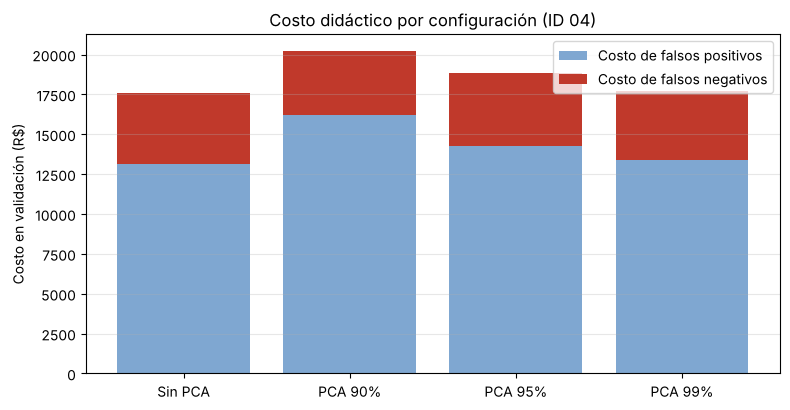

In [19]:
registros = []
for nombre, p_cfg in predicciones.items():
    tn_, fp_, fn_, tp_ = confusion_matrix(y_valid, p_cfg).ravel()
    registros.append({'configuracion': nombre, 'VN': tn_, 'FP': fp_, 'FN': fn_, 'VP': tp_,
                      'costo_FP_brl': fp_ * costo_fp, 'costo_FN_brl': fn_ * costo_fn,
                      'costo_total_brl': fp_ * costo_fp + fn_ * costo_fn})

tn_r, fp_r, fn_r, tp_r = confusion_matrix(y_valid, pred_ref).ravel()
referencia_fila = {'configuracion': 'Referencia (nunca predice retraso)', 'VN': tn_r, 'FP': fp_r,
                   'FN': fn_r, 'VP': tp_r, 'costo_FP_brl': fp_r * costo_fp,
                   'costo_FN_brl': fn_r * costo_fn,
                   'costo_total_brl': fp_r * costo_fp + fn_r * costo_fn}

costos = pd.DataFrame(registros).set_index('configuracion')
costos = costos.join(comparacion[['f1', 'precision', 'recall']])
display(pd.concat([costos, pd.DataFrame([referencia_fila]).set_index('configuracion')]).round(4))

# Elección: menor costo total en validación; desempate por F1 y luego por menos variables
orden = costos.join(comparacion['n_variables_modelo']).sort_values(
    ['costo_total_brl', 'f1', 'n_variables_modelo'], ascending=[True, False, True])
modelo_elegido = orden.index[0]
print('Modelo elegido (menor costo en validación):', modelo_elegido,
      '| costo R$', int(costos.loc[modelo_elegido, 'costo_total_brl']))

ruta_costos = Path(f'reports/S12_costos_configuraciones_ID_{identificador}.csv')
costos.round(6).to_csv(ruta_costos)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(costos.index, costos['costo_FP_brl'], label='Costo de falsos positivos', color='#7fa7d1')
ax.bar(costos.index, costos['costo_FN_brl'], bottom=costos['costo_FP_brl'],
       label='Costo de falsos negativos', color='#c0392b')
ax.set_ylabel('Costo en validación (R$)')
ax.set_title(f'Costo didáctico por configuración (ID {identificador})')
ax.legend(); ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f'S12_costos_ID_{identificador}.png', dpi=150)
plt.show()

**Decisión empresarial (Actividad 7).** Costos en validación (356 pedidos tardíos entre 5,250), con R\$ 8 por falso positivo y R\$ 35 por falso negativo:

| Configuración | FP | FN | Costo total |
|---|---|---|---|
| Sin PCA | 1,643 | 127 | R\$ 17,589 |
| PCA 99 % | 1,674 | 123 | R\$ 17,697 |
| PCA 95 % | 1,781 | 131 | R\$ 18,833 |
| PCA 90 % | 2,023 | 116 | R\$ 20,244 |
| Referencia (nunca avisa retraso) | 0 | 356 | R\$ 12,460 |

**Modelo elegido: regresión logística sin PCA.** Tiene el menor costo entre las cuatro configuraciones, el mejor ROC-AUC y AP, y conserva coeficientes interpretables por variable. PCA 99 % es una alternativa casi equivalente (+R\$ 108, 0.6 %) si se necesitara un modelo con menos variables, pero aquí no aporta ventaja de costo ni de desempeño. La elección usa solo validación; `test` no se tocó.

**Advertencia para la decisión:** las cuatro configuraciones cuestan más que la referencia que nunca alerta (R\$ 12,460). Con `class_weight='balanced'` y umbral 0.5 el modelo marca 1,872 de 5,250 pedidos (35.7 %) para atrapar 229 de los 356 tardíos, y las 1,643 falsas alarmas pesan más que los falsos negativos que evita. Con estos costos, avisar un pedido conviene cuando su probabilidad de retraso supera 8 / (8 + 35) ≈ 0.19. Por eso el modelo elegido sirve como base, pero antes de usarlo en operación hay que ajustar el umbral de decisión (la mejora propuesta para la semana 13).

### Actividad 8. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

Se compara la distribución del valor del flete entre pedidos tardíos y pedidos a tiempo (solo `train`).

- **H0:** `valor_flete` tiene la misma distribución en pedidos tardíos y a tiempo.
- **H1:** las distribuciones son distintas (prueba bilateral).
- Nivel de significancia: α = 0,05.

n tardíos: 1660 | n a tiempo: 22840
Mediana flete tardíos: R$ 18.23 | a tiempo: R$ 17.16
Media flete tardíos:   R$ 25.31 | a tiempo: R$ 22.54
Estadístico D = 0.1173 | valor p = 5.145e-19
Decisión: se rechaza H0 (alfa = 0.05)
Fracción de valores repetidos en valor_flete (train): 0.813


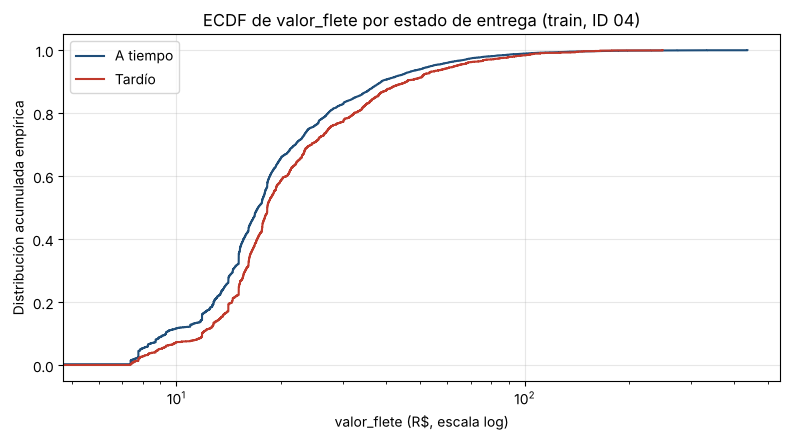

In [20]:
from scipy.stats import ks_2samp

flete_tardio = train.loc[train['is_late'] == 1, 'valor_flete']
flete_a_tiempo = train.loc[train['is_late'] == 0, 'valor_flete']

ks = ks_2samp(flete_tardio, flete_a_tiempo, alternative='two-sided')
alfa = 0.05
print(f'n tardíos: {len(flete_tardio)} | n a tiempo: {len(flete_a_tiempo)}')
print(f'Mediana flete tardíos: R$ {flete_tardio.median():.2f} | a tiempo: R$ {flete_a_tiempo.median():.2f}')
print(f'Media flete tardíos:   R$ {flete_tardio.mean():.2f} | a tiempo: R$ {flete_a_tiempo.mean():.2f}')
print(f'Estadístico D = {ks.statistic:.4f} | valor p = {ks.pvalue:.3e}')
print('Decisión:', 'se rechaza H0' if ks.pvalue < alfa else 'no se rechaza H0', f'(alfa = {alfa})')
print('Fracción de valores repetidos en valor_flete (train):',
      round(1 - train['valor_flete'].nunique() / len(train), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for datos, etiqueta, color in [(flete_a_tiempo, 'A tiempo', '#1f4e79'), (flete_tardio, 'Tardío', '#c0392b')]:
    x = np.sort(datos.values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', label=etiqueta, color=color)
ax.set_xscale('log'); ax.set_xlabel('valor_flete (R$, escala log)'); ax.set_ylabel('Distribución acumulada empírica')
ax.set_title(f'ECDF de valor_flete por estado de entrega (train, ID {identificador})')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f'S12_ks_valor_flete_ID_{identificador}.png', dpi=150)
plt.show()

**Interpretación (Actividad 8).** El estadístico es D = 0.1173 con valor p = 5.1e-19, muy por debajo de α = 0.05, así que **se rechaza H0**: la distribución de `valor_flete` no es la misma en pedidos tardíos y a tiempo. Los tardíos tienen fletes mayores (mediana R\$ 18.23 frente a R\$ 17.16; media R\$ 25.31 frente a R\$ 22.54). D indica que la mayor distancia entre las dos distribuciones acumuladas es de unos 11.7 puntos porcentuales, un efecto moderado-pequeño: el flete aporta señal, pero no separa por sí solo los pedidos tardíos.

**Limitación metodológica:** KS supone una variable continua, y `valor_flete` es una suma de fletes con muchos valores repetidos (81.3 % de los pedidos comparten su valor con otro). Con empates el valor p exacto es aproximado (la prueba tiende a ser conservadora, por lo que el rechazo se mantiene), y además la prueba solo dice que las distribuciones difieren, no por qué: el flete también depende de la distancia, el peso y la región, de modo que no puede leerse como causa del retraso.

## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta:
El modelo de referencia (DummyClassifier) obtuvo Accuracy de 0.932, pero Recall y F1 de 0.000: solo refleja que el 6.77 % de los pedidos son tardíos y nunca detecta uno. La regresión logística con `class_weight='balanced'` obtuvo Accuracy de 0.6621, Recall de 0.6433 y F1 de 0.2052 (Precision 0.1221, ROC-AUC 0.7162). Su Accuracy es menor que la de la referencia porque el modelo marca muchos pedidos a tiempo como tardíos, pero Accuracy es engañosa con una clase tan minoritaria; Recall y F1 muestran que el modelo sí identifica retrasos.

Justificación de `class_weight`: probé ambas opciones en validación. Con `None` el modelo no marca ningún pedido como tardío (Recall 0.000, F1 0.000, igual que la referencia), aunque su ROC-AUC es casi el mismo (0.7150 frente a 0.7162): ordena igual de bien, pero con el umbral de 0.5 ninguna probabilidad llega a ese valor. `'balanced'` da más peso a la clase tardía y produce alertas útiles. Su costo es que genera 1,647 falsos positivos y, con los costos del ejercicio, queda más caro (R\$ 17,621) que no alertar nunca (R\$ 12,460); esto se resuelve ajustando el umbral (pregunta 3).


2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:
Los segmentos con 100 % de error (por ejemplo PB, MA, TO, SE o RN en octubre) tienen solo 1 o 2 pedidos y no son interpretables. Entre los segmentos con al menos 30 pedidos, los ocho con mayor error son todos de Rio de Janeiro (RJ), con error entre 62 % y 79 % (por ejemplo, agosto: 79.25 % con 53 pedidos). A nivel de estado, con más de 100 pedidos, el error es de 69.83 % en ES (116 pedidos), 64.55 % en BA (189) y 64.44 % en RJ (658). Por mes, agosto es el peor (51.67 % de error con 569 pedidos).

Relación con el costo: en RJ la tasa real de retraso es 13.07 %, así que como máximo 13 de cada 100 pedidos de RJ pueden ser falsos negativos y al menos 51 de cada 100 son falsos positivos. En todo el conjunto de validación hubo 1,647 FP y 127 FN: los FP suman R\$ 13,176 y los FN R\$ 4,445, para un costo total de R\$ 17,621. Aunque un FN cuesta más (R\$ 35 frente a R\$ 8), el volumen de falsas alarmas concentradas en estados con más retrasos domina el costo.


3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta:
Propuesta: elegir el umbral de decisión según el costo (ya no 0.5), y mejorar el tratamiento de las variables geográficas (`customer_state`, `estado_vendedor`) con Target Encoding calculado solo con `train` y una variable de interacción entre estado del cliente y del vendedor. El umbral debe quedar cerca de la probabilidad de equilibrio 8 / (8 + 35) ≈ 0.19 y se afinará en validación.

Verificación: se entrenará el nuevo pipeline solo con `X_train`, con la misma semilla (1004) y las mismas particiones del ID 04, y se evaluará en `X_valid`. La mejora se acepta si el costo baja de R\$ 17,621 (modelo de la Actividad 4) y, idealmente, de R\$ 12,460 (la referencia que nunca alerta), sin bajar el ROC-AUC (0.7162) ni el AP. Los datos de `test` se usarán una sola vez al final.


## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [21]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
    'pca_componentes': {f'{int(u*100)}%': k for u, k in n_comp.items()},
    'pca_n_variables_preprocesadas': int(n_total),
    'comparacion_configuraciones': comparacion.reset_index().round(6).to_dict(orient='records'),
    'costos_configuraciones': costos.reset_index().round(6).to_dict(orient='records'),
    'modelo_elegido': modelo_elegido,
    'ks_valor_flete': {'estadistico_D': float(ks.statistic), 'valor_p': float(ks.pvalue),
                       'alfa': alfa, 'n_tardios': int(len(flete_tardio)),
                       'n_a_tiempo': int(len(flete_a_tiempo))},
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports/S12_resultados_ID_04.json
Si no se descargó automáticamente, guarde manualmente: reports/S12_resultados_ID_04.json


/tmp/ipykernel_279/3217234246.py:8: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
